<a href="https://colab.research.google.com/github/Japi20/Data-201-Project1/blob/main/Data_201_Project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATA 201 Project 1: Classification in Practice

Jorge Pineda

Breast Cancer Wisconsin (Diagnostic)

This project investigates whether measurements of cell nuclei can distinguish malignant from benign breast-mass samples, with particular attention to malignant samples incorrectly classified as benign.

In [4]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, roc_curve, roc_auc_score)

In [5]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


## Part 1: Understand Your Problem

1. What does each row represent? What is the response and what are its classes?

Each row represents one breast-mass sample collected through fine-needle aspiration. The measurements summarize cell nuclei in a digitized image of the sample. The response column, y, records the diagnosis as B for benign or M for malignant. [1]

The original diagnostic study describes an image-analysis procedure using approximately 10–20 selected nuclei per sample. The CSV contains the resulting summaries, **without** the individual nuclear measurements or the exact number of nuclei for each row. Nucleus counts can affect standard errors and the opportunity to observe extreme values, so these counts would help assess differences between samples. [2]

In [6]:
file_path = "/content/drive/MyDrive/Data_201/Datasets/brca.csv"
brca = pd.read_csv(file_path)
brca.head()

,Unnamed: 0,x.radius_mean,x.texture_mean,x.perimeter_mean,x.area_mean,x.smoothness_mean,x.compactness_mean,x.concavity_mean,x.concave_pts_mean,x.symmetry_mean,...,x.texture_worst,x.perimeter_worst,x.area_worst,x.smoothness_worst,x.compactness_worst,x.concavity_worst,x.concave_pts_worst,x.symmetry_worst,x.fractal_dim_worst,y
0,1,13.540,14.36,87.46,566.3,0.09779,0.08129,0.06664,0.047810,0.1885,...,19.26,99.70,711.2,0.14400,0.17730,0.23900,0.12880,0.2977,0.07259,B
1,2,13.080,15.71,85.63,520.0,0.10750,0.12700,0.04568,0.031100,0.1967,...,20.49,96.09,630.5,0.13120,0.27760,0.18900,0.07283,0.3184,0.08183,B
2,3,9.504,12.44,60.34,273.9,0.10240,0.06492,0.02956,0.020760,0.1815,...,15.66,65.13,314.9,0.13240,0.11480,0.08867,0.06227,0.2450,0.07773,B
3,4,13.030,18.42,82.61,523.8,0.08983,0.03766,0.02562,0.029230,0.1467,...,22.81,84.46,545.9,0.09701,0.04619,0.04833,0.05013,0.1987,0.06169,B
4,5,8.196,16.84,51.71,201.9,0.08600,0.05943,0.01588,0.005917,0.1769,...,21.96,57.26,242.2,0.12970,0.13570,0.06880,0.02564,0.3105,0.07409,B


In [7]:
print(brca.shape)
print(brca.columns.tolist())

(569, 32)
['Unnamed: 0', 'x.radius_mean', 'x.texture_mean', 'x.perimeter_mean', 'x.area_mean', 'x.smoothness_mean', 'x.compactness_mean', 'x.concavity_mean', 'x.concave_pts_mean', 'x.symmetry_mean', 'x.fractal_dim_mean', 'x.radius_se', 'x.texture_se', 'x.perimeter_se', 'x.area_se', 'x.smoothness_se', 'x.compactness_se', 'x.concavity_se', 'x.concave_pts_se', 'x.symmetry_se', 'x.fractal_dim_se', 'x.radius_worst', 'x.texture_worst', 'x.perimeter_worst', 'x.area_worst', 'x.smoothness_worst', 'x.compactness_worst', 'x.concavity_worst', 'x.concave_pts_worst', 'x.symmetry_worst', 'x.fractal_dim_worst', 'y']


##### Inspect data types and non-missing counts

info() reports a summary for each column. The diagnosis is categorical text and the 30 nuclear measurements are numeric.

In [8]:
brca.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           569 non-null    int64  
 1   x.radius_mean        569 non-null    float64
 2   x.texture_mean       569 non-null    float64
 3   x.perimeter_mean     569 non-null    float64
 4   x.area_mean          569 non-null    float64
 5   x.smoothness_mean    569 non-null    float64
 6   x.compactness_mean   569 non-null    float64
 7   x.concavity_mean     569 non-null    float64
 8   x.concave_pts_mean   569 non-null    float64
 9   x.symmetry_mean      569 non-null    float64
 10  x.fractal_dim_mean   569 non-null    float64
 11  x.radius_se          569 non-null    float64
 12  x.texture_se         569 non-null    float64
 13  x.perimeter_se       569 non-null    float64
 14  x.area_se            569 non-null    float64
 15  x.smoothness_se      569 non-null    flo

The file contains 569 observations and 32 columns, including 30 nuclear measurements, the diagnosis, and an exported row-number column.

2. Select useful predictors

I select the 30 nuclear measurements as candidate predictors. They summarize ten characteristics: radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, and fractal dimension. Each characteristic has a mean, standard error, and worst summary. Worst is the average of the three largest measurements for that characteristic. [1, 2]

A small number of abnormal nuclei may carry useful information that an average across all measured nuclei makes less visible. The researchers describe using extreme summaries to retain this information and averaging three values to **reduce possible noise**. Based on the literature reviewed and the researchers' interpretations, and considering my limited domain knowledge of the biology involved, this seems like sufficient reason to consider the worst summaries alongside the means.[3]

The first five rows all have diagnosis B. A quick visual check confirm that the file is ordered by diagnosis.
Unnamed: 0 is a row index with no biological meaning and therefor is excluded.
The diagnosis column is also excluded from the predictors because it is the target.

I encode **B as 0 and M as 1**, making malignant the positive class for the error counts and evaluation metrics.


In [9]:
X = brca.drop(columns=["Unnamed: 0", "y"])
y = brca["y"].map({"B": 0, "M": 1})

print("Predictor table shape:", X.shape)
print("\n Encoded Target Counts")
print(y.value_counts())

Predictor table shape: (569, 30)

 Encoded Target Counts
y
0    357
1    212
Name: count, dtype: int64


3. Examine the response distribution

In [10]:
class_counts = brca["y"].value_counts()
class_percentages = brca["y"].value_counts(normalize=True) * 100

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percent": class_percentages.round(2)
})
class_summary

,Count,Percent
y,,
B,357,62.74
M,212,37.26


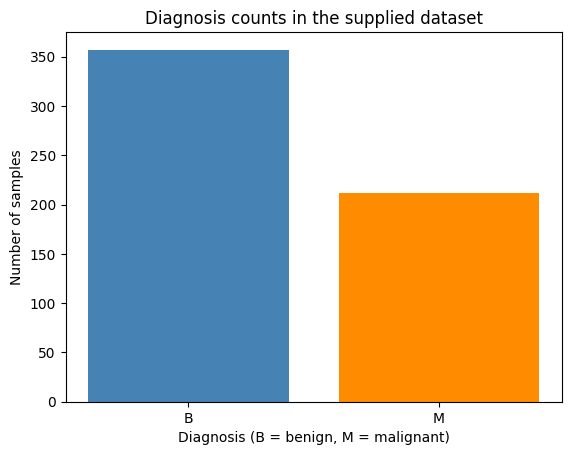

In [11]:
plt.bar(class_counts.index, class_counts.values, color=["steelblue", "darkorange"])
plt.xlabel("Diagnosis (B = benign, M = malignant)")
plt.ylabel("Number of samples")
plt.title("Diagnosis counts in the supplied dataset")
plt.show()

There are 357 benign samples (62.74%) and 212 malignant samples (37.26%). The classes are unequal while maintaining substantial representation. Predicting benign for every sample would achieve 62.74% accuracy while missing all 212 malignant samples.

4. Define false positives and false negatives

A false positive is a benign sample classified as malignant. A false negative is a malignant sample classified as benign.

5. Which error is more concerning?

False negatives are far more concerning in this case because a missed malignant tumor could delay further investigation and treatment. False positives still matter to avoid a patients anxiety and additional investigations/costs.

In this project, sensitivity measures the proportion of malignant samples correctly identified. I will examine it alongside the false-negative count to assess missed malignancies. Specificity measures the proportion of benign samples correctly classified. I will also report the false-positive count. And these measures explain consequences that the overall percentage of correct predictions can hide.

## Part 2: Explore and Prepare the Data

1. Investigate features and predictors

The column information checked the data types and the number of available values (all 30 predictors numeric, target contains the text labels B and M).

Comparisons of **predictor distributions by diagnosis** will use the training portion after the test set is reserved. Keeping model exploration separate from the final evaluation.

2. Check for missing values

In [12]:
print(brca.isna().sum())
print("Exact duplicate predictor rows:", X.duplicated().sum())

Unnamed: 0             0
x.radius_mean          0
x.texture_mean         0
x.perimeter_mean       0
x.area_mean            0
x.smoothness_mean      0
x.compactness_mean     0
x.concavity_mean       0
x.concave_pts_mean     0
x.symmetry_mean        0
x.fractal_dim_mean     0
x.radius_se            0
x.texture_se           0
x.perimeter_se         0
x.area_se              0
x.smoothness_se        0
x.compactness_se       0
x.concavity_se         0
x.concave_pts_se       0
x.symmetry_se          0
x.fractal_dim_se       0
x.radius_worst         0
x.texture_worst        0
x.perimeter_worst      0
x.area_worst           0
x.smoothness_worst     0
x.compactness_worst    0
x.concavity_worst      0
x.concave_pts_worst    0
x.symmetry_worst       0
x.fractal_dim_worst    0
y                      0
dtype: int64
Exact duplicate predictor rows: 0


The file has **no missing values** and **no repeated rows** of the same 30 predictor values. No imputation or duplicate removal is needed.


3. Check whether categorical predictors need encoding

There are no categorical predictors to encode. The diagnosis was mapped to 0 and 1 in Part 1. The check below confirms that every label was mapped.

In [13]:
print("Missing values after target encoding:", y.isna().sum())

Missing values after target encoding: 0


4. Divide the data, then use k-fold CV on training data

I split 25% of the observations for testing and use 75% for training. Shuffling mixes the diagnosis-ordered rows, and stratification keeps the class proportions equal across the two portions. The seed fixes the split so the comparison can be reproduced.

I use training data for model-guiding exploration so that the held-out test set remains an independent final evaluation.

In [21]:
import seaborn as sns

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=1,
    shuffle=True,
    stratify=y)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test), "\n")

split_counts = pd.DataFrame({
    "Training count": y_train.value_counts(),
    "Test count": y_test.value_counts(),
    "Training percent": (y_train.value_counts(normalize=True) * 100).round(2),
    "Test percent": (y_test.value_counts(normalize=True) * 100).round(2)
})
split_counts


Training samples: 426
Test samples: 143 



,Training count,Test count,Training percent,Test percent
y,,,,
0,267,90,62.68,62.94
1,159,53,37.32,37.06


The split gives 426 training samples and 143 test samples.

Training contains 267 benign and 159 malignant samples. The test set contains 90 benign and 53 malignant samples.



---


Five-fold validation uses four training folds to fit each model and the remaining fold to validate it, repeating until every fold has been used for validation. All models use the same folds.

In [22]:
kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

## Training-data exploration (Part 2, question 1)

As an added exploration, these plots compare the three radius summaries by diagnosis. They provide a direct view of the mean, SE, and worst summaries introduced in Part 1.

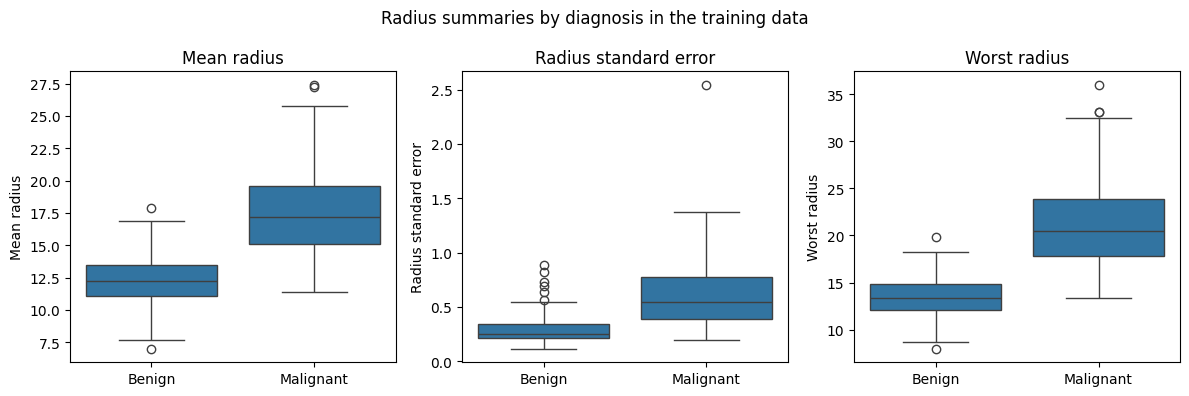

In [23]:
training_data = X_train.copy()
training_data["Diagnosis"] = y_train.map({0: "Benign", 1: "Malignant"})

radius_features = ["x.radius_mean", "x.radius_se", "x.radius_worst"]
radius_titles = ["Mean radius", "Radius standard error", "Worst radius"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for i in range(3):
    sns.boxplot(
        data=training_data,
        x="Diagnosis",
        y=radius_features[i],
        order=["Benign", "Malignant"],
        ax=axes[i]
    )
    axes[i].set_title(radius_titles[i])
    axes[i].set_xlabel("")
    axes[i].set_ylabel(radius_titles[i])

plt.suptitle("Radius summaries by diagnosis in the training data")
plt.tight_layout()
plt.show()

Malignant samples tend to have larger radius summaries, with overlap between the groups. The distributions support using radius information for classification (some large values could represent useful diagnostic information or measurement errors, but without evidence to distinguish them, they are kept in the dataset).
Radius, perimeter, and area describe related aspects of nuclear size.

In [24]:
size_features = ["x.radius_mean", "x.perimeter_mean", "x.area_mean"]
X_train[size_features].corr()

,x.radius_mean,x.perimeter_mean,x.area_mean
x.radius_mean,1.000000,0.997616,0.987277
x.perimeter_mean,0.997616,1.000000,0.986397
x.area_mean,0.987277,0.986397,1.000000


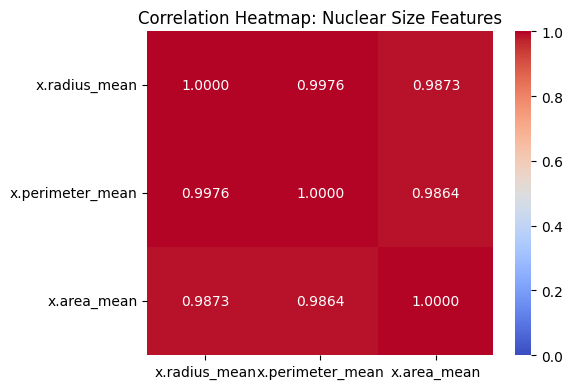

In [26]:

corr_matrix = X_train[size_features].corr()

plt.figure(figsize=(6, 4))

sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=0, vmax=1, fmt=".4f")
plt.title("Correlation Heatmap: Nuclear Size Features")
plt.tight_layout()
plt.show()

The three correlations exceed 0.98. I retain the same 30 predictors for all four models and will account for this strong overlap when interpreting the covariance-based models.

5. Determine whether predictors should be standardized

In [27]:
X_train[["x.radius_mean", "x.area_mean", "x.smoothness_mean"]].describe()

,x.radius_mean,x.area_mean,x.smoothness_mean
count,426.000000,426.000000,426.000000
mean,14.108185,652.815493,0.096418
std,3.503540,347.269922,0.014180
min,6.981000,143.500000,0.052630
25%,11.710000,420.475000,0.085320
50%,13.415000,554.300000,0.096180
75%,15.772500,782.675000,0.105250
max,27.420000,2501.000000,0.163400


Mean area ranges from 143.5 to 2501 in the training data, while mean smoothness ranges from about 0.053 to 0.163.

Scaling prevents the larger numerical range from dominating KNN distances. It also puts predictors on comparable scales for logistic regression's coefficient penalty.
Each model uses a StandardScaler pipeline. During validation, the scaler learns the mean and standard deviation from the four fitting folds and applies those values to the validation fold.
LDA and QDA already account for scale through their covariance calculations. I use the same standardized inputs throughout the comparison, and QDA's regularization is applied on this scale.

## Part 3: Build Your Classifiers
All settings in this section are chosen with training-data validation. Final test performance has not yet been examined.

Choosing model settings such as K requires a measure of validation performance. From Lab 6, I use mean five-fold validation ROC-AUC to compare how well models rank malignant samples above benign samples before choosing a classification threshold. I will then use validation sensitivity and false-positive counts to choose thresholds, giving particular attention to missed malignant samples.


1. Logistic Regression

Logistic regression models the probability of malignancy using a linear combination of the predictors. I keep the default regularization strength and allow up to 1000 iterations for the coefficient calculation.

In [28]:
logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

logreg_cv = cross_val_score(
    logreg, X_train, y_train, cv=kfold, scoring="roc_auc"
)

print("Logistic regression mean validation ROC-AUC:", logreg_cv.mean())

Logistic regression mean validation ROC-AUC: 0.9963443396226415


2. LDA

LDA estimates a mean for each class and a shared covariance matrix, producing a linear decision boundary.

In [29]:
lda = make_pipeline(
    StandardScaler(),
    LinearDiscriminantAnalysis()
)

lda_cv = cross_val_score(
    lda, X_train, y_train, cv=kfold, scoring="roc_auc"
)

print("LDA mean validation ROC-AUC:", lda_cv.mean())

LDA mean validation ROC-AUC: 0.9899764150943395


3. QDA

QDA estimates a separate covariance matrix for each class, allowing a curved decision boundary. The initial fit failed because a class covariance matrix was not full rank at the implementation's numerical tolerance.

In [30]:
reg_values = [0.001, 0.01, 0.1, 0.5]
qda_cv_scores = []

start = time.perf_counter()

for reg in reg_values:
    model = make_pipeline(
        StandardScaler(),
        QuadraticDiscriminantAnalysis(reg_param=reg)
    )
    scores = cross_val_score(
        model, X_train, y_train, cv=kfold, scoring="roc_auc"
    )
    qda_cv_scores.append(scores.mean())

qda_tuning_seconds = time.perf_counter() - start
best_reg = reg_values[np.argmax(qda_cv_scores)]

print("Selected reg_param:", best_reg)
pd.DataFrame({"reg_param": reg_values, "Mean validation ROC-AUC": qda_cv_scores})

Selected reg_param: 0.1


,reg_param,Mean validation ROC-AUC
0,0.001,0.987622
1,0.010,0.989389
2,0.100,0.991392
3,0.500,0.990566


I used regularization to stabilize QDA’s covariance estimates. I compared four regularization strengths using five-fold cross-validation and selected 0.1 because it had the highest mean validation ROC-AUC.

In [31]:
qda = make_pipeline(
    StandardScaler(),
    QuadraticDiscriminantAnalysis(reg_param=best_reg)
)

4. KNN

KNN predicts from nearby training observations. I compare ten values from 1 to 51 neighbors, covering small local neighborhoods and broader ones. Each fitting fold contains at least 340 observations, so all candidates are valid.
The pipeline scales predictors separately within each fold before calculating distances

In [32]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51]
knn_cv_scores = []

start = time.perf_counter()

for k in k_values:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )
    scores = cross_val_score(
        model, X_train, y_train, cv=kfold, scoring="roc_auc"
    )
    knn_cv_scores.append(scores.mean())

knn_tuning_seconds = time.perf_counter() - start
best_k = k_values[np.argmax(knn_cv_scores)]

print("Selected K:", best_k)
pd.DataFrame({"K": k_values, "Mean validation ROC-AUC": knn_cv_scores})

Selected K: 11


,K,Mean validation ROC-AUC
0,1,0.964398
1,3,0.985849
2,5,0.984486
3,7,0.986677
4,9,0.986209
5,11,0.992154
6,15,0.991682
7,21,0.991442
8,31,0.989613
9,51,0.989731


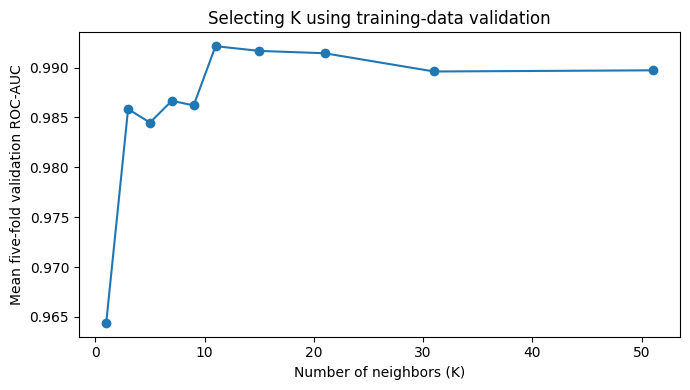

In [33]:
plt.figure(figsize=(7, 4))
plt.plot(k_values, knn_cv_scores, marker="o")
plt.xlabel("Number of neighbors (K)")
plt.ylabel("Mean five-fold validation ROC-AUC")
plt.title("Selecting K using training-data validation")
plt.tight_layout()
plt.show()

The selected K is 11, with mean validation ROC-AUC of 0.9922. It has the highest mean score among the candidates evaluated. This selection is hyperparameter tuning.

In [35]:
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=best_k)
)

validation_results = pd.DataFrame({
    "Model": ["Logistic Regression", "LDA", "QDA", "KNN"],
    "Mean validation ROC-AUC": [
        logreg_cv.mean(),
        lda_cv.mean(),
        max(qda_cv_scores),
        max(knn_cv_scores)
    ]
})
validation_results

,Model,Mean validation ROC-AUC
0,Logistic Regression,0.996344
1,LDA,0.989976
2,QDA,0.991392
3,KNN,0.992154


Logistic regression has the highest mean validation ROC-AUC at this point. The final recommendation will also account for missed malignant samples and false positives.


---



#### Fit the four selected models and generate test predictions

Each selected pipeline is now fitted on all 426 training samples. The table reports test predictions and estimated probabilities of malignancy. Labels use the default decision rule with a 0.5 probability cutoff (the true test diagnoses in Part 4, after threshold selection, using validation predictions)

In [36]:
models = {
    "Logistic Regression": logreg,
    "LDA": lda,
    "QDA": qda,
    "KNN": knn
}

test_predictions = pd.DataFrame()
timing_rows = []

for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start

    start = time.perf_counter()
    test_predictions[name + " prediction"] = model.predict(X_test)
    test_predictions[name + " P(M)"] = model.predict_proba(X_test)[:, 1]
    prediction_seconds = time.perf_counter() - start

    timing_rows.append({
        "Model": name,
        "Final fit seconds": fit_seconds,
        "Labels and probabilities seconds": prediction_seconds
    })

test_predictions.to_csv("DATA201_Project1_Part3_TestPredictions.csv", index=False)
test_predictions

,Logistic Regression prediction,Logistic Regression P(M),LDA prediction,LDA P(M),QDA prediction,QDA P(M),KNN prediction,KNN P(M)
0,0,0.002295,0,0.000311,0,1.428433e-04,0,0.0
1,0,0.003852,0,0.000172,0,2.419341e-04,0,0.0
2,1,1.000000,1,0.999967,1,1.000000e+00,1,1.0
3,0,0.000879,0,0.000088,0,5.177732e-04,0,0.0
4,0,0.000024,0,0.000004,0,2.366036e-06,0,0.0
...,...,...,...,...,...,...,...,...
138,0,0.001075,0,0.000186,0,1.608662e-04,0,0.0
139,0,0.007201,0,0.003383,0,8.413112e-04,0,0.0
140,0,0.000106,0,0.000008,0,2.944137e-06,0,0.0
141,0,0.013113,0,0.001336,0,4.282763e-04,0,0.0


The prediction table contains all 143 test samples in the order returned by the split. P(M) is the model's estimated probability of malignancy. Final fitting and prediction times are recorded separately from tuning time.

In [37]:
print("QDA tuning seconds:", qda_tuning_seconds)
print("KNN tuning seconds:", knn_tuning_seconds)
pd.DataFrame(timing_rows)

QDA tuning seconds: 0.4552528629992594
KNN tuning seconds: 0.6810736380029994


,Model,Final fit seconds,Labels and probabilities seconds
0,Logistic Regression,0.015830,0.008226
1,LDA,0.009594,0.007767
2,QDA,0.008473,0.006522
3,KNN,0.006019,0.014815


These are single-run timings on this dataset and execution environment. KNN tuning fits 50 models across the ten candidates and five folds, while its final fit uses the selected K once.

# Part 4: Evaluate Your Models

1. Choose thresholds and produce confusion matrices

The positive class is malignant, coded as 1.
A false negative is a malignant sample classified as benign. I am giving particular attention to this error given the consequences of a misdiagnosis.

I first use training-data validation to choose a threshold for each model. Final test performance has not yet been examined at this stage. I set a validation sensitivity target of at least 98%, which allows at most 3 misses among the 159 malignant training samples. This target is a project choice based on the error priority established in Part 1.
For each model, I choose the highest tested threshold that meets this target. Raising the threshold reduces or preserves the number of false positives. I then prefer the model with the fewest validation false positives. Ties are resolved by fewer false negatives and then higher mean validation ROC-AUC.

In [40]:
candidate_thresholds = [0.001, 0.005, 0.01, 0.02, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50]
sensitivity_target = 0.98

Validation probabilities


Each training sample receives a probability from a model fitted on the other four folds. The scaler is also fitted within those folds.

These probabilities allow compare thresholds without examining test performance.

In [38]:
logreg_validation_prob = cross_val_predict(
    logreg, X_train, y_train, cv=kfold, method="predict_proba"
)[:, 1]

lda_validation_prob = cross_val_predict(
    lda, X_train, y_train, cv=kfold, method="predict_proba"
)[:, 1]

qda_validation_prob = cross_val_predict(
    qda, X_train, y_train, cv=kfold, method="predict_proba"
)[:, 1]

knn_validation_prob = cross_val_predict(
    knn, X_train, y_train, cv=kfold, method="predict_proba"
)[:, 1]

Threshold comparisons

A sample is classified as malignant when its estimated probability reaches the threshold. Lower thresholds flag more samples and can reduce missed malignancies while increasing false positives.
The initial range of 0.05 to 0.50 did not achieve 98% validation sensitivity for LDA or QDA. I extendd the grid to lower values using validation results. The following tables show the complete grid. Confusion-matrix counts are read in the order TN, FP, FN, TP.

Logistic Regression

In [41]:
logreg_threshold_rows = []

for threshold in candidate_thresholds:
    validation_labels = (logreg_validation_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_train, validation_labels, labels=[0, 1]
    ).ravel()

    logreg_threshold_rows.append({
        "Threshold": threshold,
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "False negatives": fn,
        "False positives": fp
    })

logreg_threshold_results = pd.DataFrame(logreg_threshold_rows)
logreg_threshold_results

,Threshold,Sensitivity,Specificity,False negatives,False positives
0,0.001,1.000000,0.415730,0,156
1,0.005,0.993711,0.599251,1,107
2,0.010,0.993711,0.681648,1,85
3,0.020,0.993711,0.760300,1,64
4,0.050,0.993711,0.857678,1,38
5,0.100,0.981132,0.898876,3,27
6,0.200,0.981132,0.958801,3,11
7,0.300,0.981132,0.970037,3,8
8,0.400,0.981132,0.988764,3,3
9,0.500,0.974843,0.996255,4,1


LDA

In [42]:
lda_threshold_rows = []

for threshold in candidate_thresholds:
    validation_labels = (lda_validation_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_train, validation_labels, labels=[0, 1]
    ).ravel()

    lda_threshold_rows.append({
        "Threshold": threshold,
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "False negatives": fn,
        "False positives": fp
    })

lda_threshold_results = pd.DataFrame(lda_threshold_rows)
lda_threshold_results

,Threshold,Sensitivity,Specificity,False negatives,False positives
0,0.001,0.987421,0.651685,2,93
1,0.005,0.987421,0.794007,2,55
2,0.010,0.981132,0.857678,3,38
3,0.020,0.981132,0.891386,3,29
4,0.050,0.974843,0.943820,4,15
5,0.100,0.962264,0.977528,6,6
6,0.200,0.949686,0.988764,8,3
7,0.300,0.949686,1.000000,8,0
8,0.400,0.937107,1.000000,10,0
9,0.500,0.924528,1.000000,12,0


QDA

In [43]:
qda_threshold_rows = []

for threshold in candidate_thresholds:
    validation_labels = (qda_validation_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_train, validation_labels, labels=[0, 1]
    ).ravel()

    qda_threshold_rows.append({
        "Threshold": threshold,
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "False negatives": fn,
        "False positives": fp
    })

qda_threshold_results = pd.DataFrame(qda_threshold_rows)
qda_threshold_results

,Threshold,Sensitivity,Specificity,False negatives,False positives
0,0.001,0.993711,0.689139,1,83
1,0.005,0.993711,0.831461,1,45
2,0.010,0.987421,0.868914,2,35
3,0.020,0.981132,0.928839,3,19
4,0.050,0.968553,0.962547,5,10
5,0.100,0.968553,0.977528,5,6
6,0.200,0.968553,0.988764,5,3
7,0.300,0.949686,0.988764,8,3
8,0.400,0.949686,0.988764,8,3
9,0.500,0.943396,0.992509,9,2


KNN

In [44]:
knn_threshold_rows = []

for threshold in candidate_thresholds:
    validation_labels = (knn_validation_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_train, validation_labels, labels=[0, 1]
    ).ravel()

    knn_threshold_rows.append({
        "Threshold": threshold,
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "False negatives": fn,
        "False positives": fp
    })

knn_threshold_results = pd.DataFrame(knn_threshold_rows)
knn_threshold_results

,Threshold,Sensitivity,Specificity,False negatives,False positives
0,0.001,0.993711,0.767790,1,62
1,0.005,0.993711,0.767790,1,62
2,0.010,0.993711,0.767790,1,62
3,0.020,0.993711,0.767790,1,62
4,0.050,0.993711,0.767790,1,62
5,0.100,0.981132,0.898876,3,27
6,0.200,0.974843,0.936330,4,17
7,0.300,0.962264,0.962547,6,10
8,0.400,0.924528,0.977528,12,6
9,0.500,0.905660,0.992509,15,2


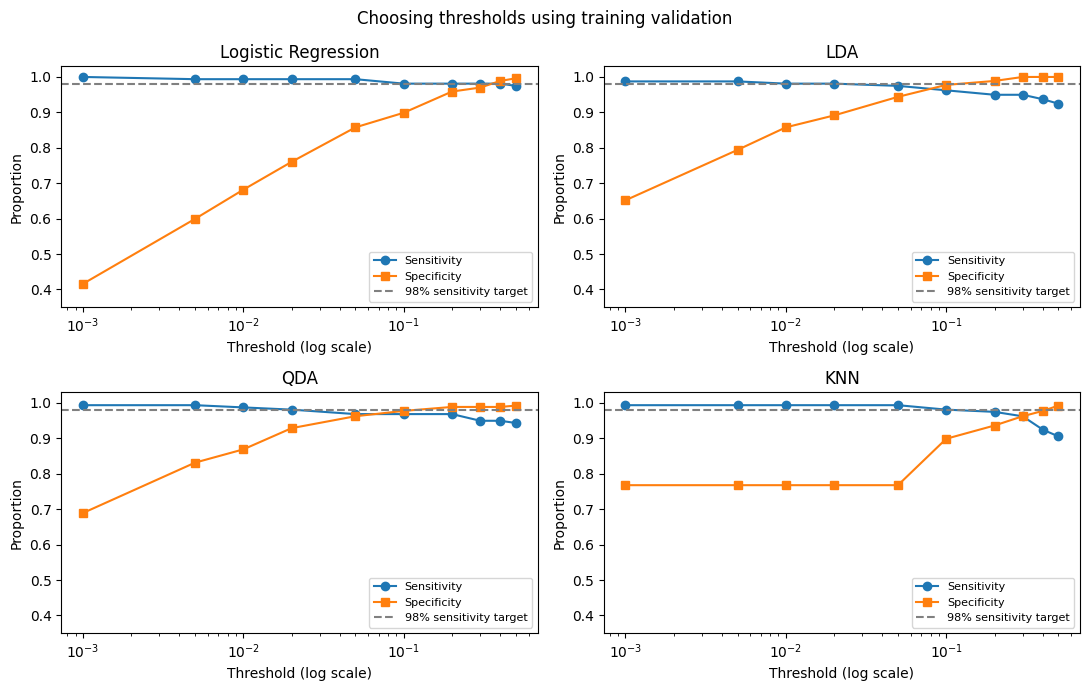

In [45]:
model_names = ["Logistic Regression", "LDA", "QDA", "KNN"]
threshold_tables = [logreg_threshold_results, lda_threshold_results,
                    qda_threshold_results, knn_threshold_results]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes = axes.ravel()

for i in range(4):
    table = threshold_tables[i]
    axes[i].plot(table["Threshold"], table["Sensitivity"], marker="o", label="Sensitivity")
    axes[i].plot(table["Threshold"], table["Specificity"], marker="s", label="Specificity")
    axes[i].axhline(sensitivity_target, color="gray", linestyle="--", label="98% sensitivity target")
    axes[i].set_xscale("log")
    axes[i].set_xlabel("Threshold (log scale)")
    axes[i].set_ylabel("Proportion")
    axes[i].set_ylim(0.35, 1.03)
    axes[i].set_title(model_names[i])
    axes[i].legend(loc="lower right", fontsize=8)

plt.suptitle("Choosing thresholds using training validation")
plt.tight_layout()
plt.show()

The logarithmic horizontal axis makes the smaller thresholds visible. The tables provide the exact thresholds and error counts.
At the selected thresholds, all four models detect 156 of the 159 malignant training samples, giving 98.11% validation sensitivity. Logistic regression produces 3 false positives, compared with 29 for LDA, 19 for QDA, and 27 for KNN. I select logistic regression at 0.40 based on this comparison.
For logistic regression, the 0.50 threshold misses 4 malignant training samples. Lowering it to 0.40 reduces that count to 3 and increases false positives from 1 to 3. Further tested reductions down to 0.10 retain the same 3 misses while producing more false positives.

In [46]:
logreg_threshold = 0.40
lda_threshold = 0.02
qda_threshold = 0.02
knn_threshold = 0.10
recommended_model = "Logistic Regression"

chosen_thresholds = pd.DataFrame({
    "Model": model_names,
    "Threshold": [logreg_threshold, lda_threshold, qda_threshold, knn_threshold]
})
chosen_thresholds

,Model,Threshold
0,Logistic Regression,0.40
1,LDA,0.02
2,QDA,0.02
3,KNN,0.10


Final test evaluation

With the thresholds and model now fixed, I can compare predictions with the held-out diagnoses for the first time. The test set contains 143 samples, including 90 benign and 53 malignant samples. The four models were fitted on all 426 training samples.
In each confusion matrix, rows show the known diagnosis and columns show the predicted diagnosis. The lower-left entry counts malignant samples incorrectly classified as benign.

In [47]:
logreg_test_prob = logreg.predict_proba(X_test)[:, 1]
logreg_test_pred = (logreg_test_prob >= logreg_threshold).astype(int)

lda_test_prob = lda.predict_proba(X_test)[:, 1]
lda_test_pred = (lda_test_prob >= lda_threshold).astype(int)

qda_test_prob = qda.predict_proba(X_test)[:, 1]
qda_test_pred = (qda_test_prob >= qda_threshold).astype(int)

knn_test_prob = knn.predict_proba(X_test)[:, 1]
knn_test_pred = (knn_test_prob >= knn_threshold).astype(int)

Logistic Regression

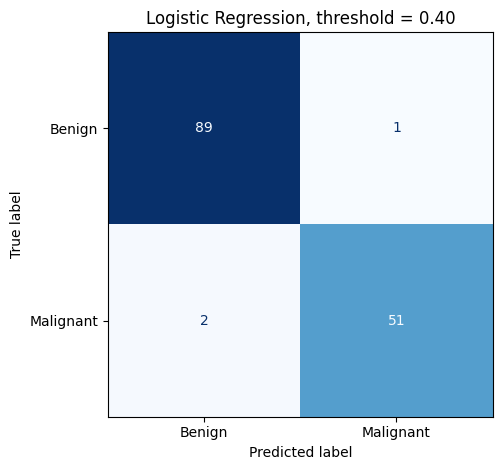

In [48]:
logreg_cm = confusion_matrix(y_test, logreg_test_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    logreg_cm, display_labels=["Benign", "Malignant"]
).plot(cmap="Blues", colorbar=False)
plt.title("Logistic Regression, threshold = 0.40")
plt.tight_layout()
plt.show()

LDA

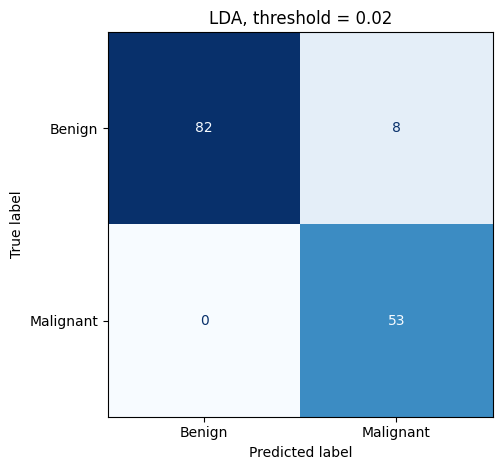

In [49]:
lda_cm = confusion_matrix(y_test, lda_test_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    lda_cm, display_labels=["Benign", "Malignant"]
).plot(cmap="Blues", colorbar=False)
plt.title("LDA, threshold = 0.02")
plt.tight_layout()
plt.show()

QDA

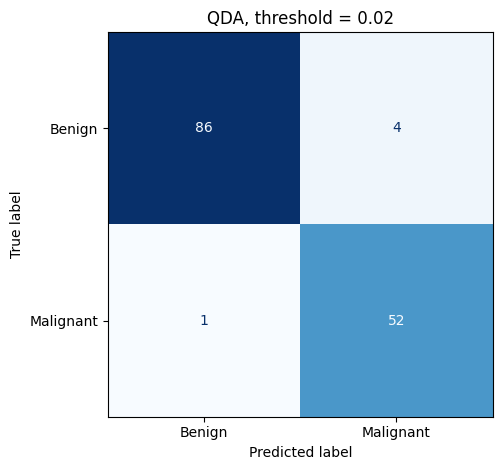

In [50]:
qda_cm = confusion_matrix(y_test, qda_test_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    qda_cm, display_labels=["Benign", "Malignant"]
).plot(cmap="Blues", colorbar=False)
plt.title("QDA, threshold = 0.02")
plt.tight_layout()
plt.show()

KNN

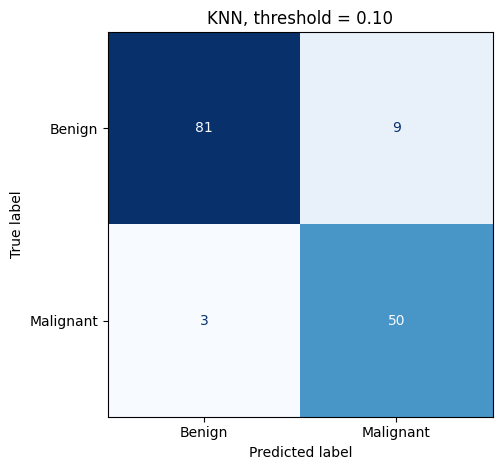

In [51]:
knn_cm = confusion_matrix(y_test, knn_test_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    knn_cm, display_labels=["Benign", "Malignant"]
).plot(cmap="Blues", colorbar=False)
plt.title("KNN, threshold = 0.10")
plt.tight_layout()
plt.show()

In [52]:
test_counts = pd.DataFrame(
    [logreg_cm.ravel(), lda_cm.ravel(), qda_cm.ravel(), knn_cm.ravel()],
    index=model_names,
    columns=["True negatives", "False positives", "False negatives", "True positives"]
)
test_counts

,True negatives,False positives,False negatives,True positives
Logistic Regression,89,1,2,51
LDA,82,8,0,53
QDA,86,4,1,52
KNN,81,9,3,50


2. Calculate the six required metrics

Accuracy is the fraction of all samples classified correctly. Precision is the fraction of predicted malignant samples that are malignant. Sensitivity, is the fraction of malignant samples detected. Specificity is the fraction of benign samples correctly classified.

F1 combines precision and sensitivity through their harmonic mean.

ROC-AUC uses the estimated malignancy probabilities across thresholds. The other five metrics below use the selected classification thresholds.

In [54]:
tn, fp, fn, tp = logreg_cm.ravel()

logreg_metrics = [
    accuracy_score(y_test, logreg_test_pred),
    precision_score(y_test, logreg_test_pred),
    recall_score(y_test, logreg_test_pred),
    tn / (tn + fp),
    f1_score(y_test, logreg_test_pred),
    roc_auc_score(y_test, logreg_test_prob)
]

In [55]:
tn, fp, fn, tp = lda_cm.ravel()

lda_metrics = [
    accuracy_score(y_test, lda_test_pred),
    precision_score(y_test, lda_test_pred),
    recall_score(y_test, lda_test_pred),
    tn / (tn + fp),
    f1_score(y_test, lda_test_pred),
    roc_auc_score(y_test, lda_test_prob)
]

In [56]:
tn, fp, fn, tp = qda_cm.ravel()

qda_metrics = [
    accuracy_score(y_test, qda_test_pred),
    precision_score(y_test, qda_test_pred),
    recall_score(y_test, qda_test_pred),
    tn / (tn + fp),
    f1_score(y_test, qda_test_pred),
    roc_auc_score(y_test, qda_test_prob)
]

In [57]:
tn, fp, fn, tp = knn_cm.ravel()

knn_metrics = [
    accuracy_score(y_test, knn_test_pred),
    precision_score(y_test, knn_test_pred),
    recall_score(y_test, knn_test_pred),
    tn / (tn + fp),
    f1_score(y_test, knn_test_pred),
    roc_auc_score(y_test, knn_test_prob)
]

In [60]:
comparison = pd.DataFrame(
    [logreg_metrics, lda_metrics, qda_metrics, knn_metrics],
    index=model_names,
    columns=["Accuracy", "Precision", "Sensitivity", "Specificity", "F1", "ROC-AUC"]
)
comparison.round(4)

,Accuracy,Precision,Sensitivity,Specificity,F1,ROC-AUC
Logistic Regression,0.9790,0.9808,0.9623,0.9889,0.9714,0.9969
LDA,0.9441,0.8689,1.0000,0.9111,0.9298,0.9918
QDA,0.9650,0.9286,0.9811,0.9556,0.9541,0.9948
KNN,0.9161,0.8475,0.9434,0.9000,0.8929,0.9895


**Logistic regression** has the highest test accuracy, precision, specificity, F1, and ROC-AUC. It misses 2 malignant samples. LDA detects all 53 malignant samples and flags 8 benign samples. QDA misses 1 malignant sample and flags 4 benign samples. KNN misses 3 malignant samples and flags 9 benign samples.
The validation sensitivity target does not guarantee the same sensitivity on new observations. Logistic regression reaches 96.23% test sensitivity, below the 98% validation target. The thresholds remain fixed after this evaluation.

# Part 5: Reflect

Sensitivity and the false-negative count are especially informative because the main concern is a malignant sample being classified as benign. Specificity and the false-positive count show how many benign samples could receive unnecessary further assessment. Precision describes how often a malignant prediction is correct.
Compared with logistic regression, LDA detects 2 additional malignant samples and produces 7 additional false positives. QDA detects 1 additional malignant sample and produces 3 additional false positives. These differences matter for the application **even though** logistic regression has the highest overall accuracy.

Always predicting benign would correctly classify 90 of 143 test samples, giving 62.94% accuracy while missing all 53 malignant samples. F1 summarizes precision and sensitivty without assigning the greater consequence we attach to a missed malignancy. ROC-AUC helps assess ranking across thresholds, and the confusion matrices show the errors at the operating thresholds.

# Part 6: ROC and AUC

The ROC curves show sensitivity against the false-positive rate as the threshold changes. A curve closer to the upper-left corner detects more malignant samples while incorrectly flagging fewer benign samples.

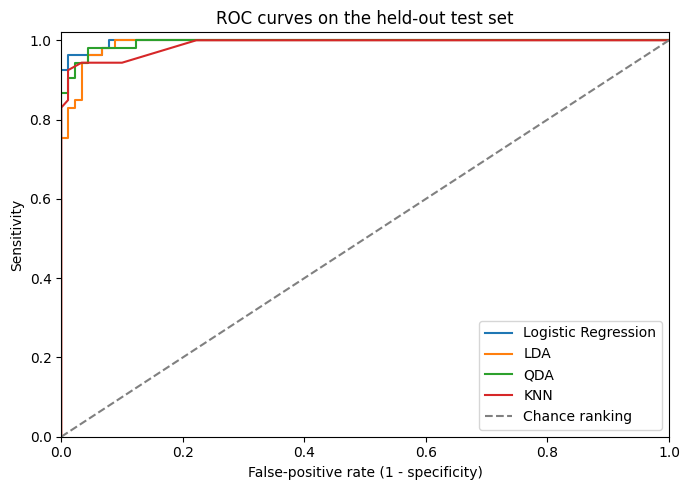

In [59]:
plt.figure(figsize=(7, 5))

fpr, tpr, roc_thresholds = roc_curve(y_test, logreg_test_prob)
plt.plot(fpr, tpr, label="Logistic Regression")

fpr, tpr, roc_thresholds = roc_curve(y_test, lda_test_prob)
plt.plot(fpr, tpr, label="LDA")

fpr, tpr, roc_thresholds = roc_curve(y_test, qda_test_prob)
plt.plot(fpr, tpr, label="QDA")

fpr, tpr, roc_thresholds = roc_curve(y_test, knn_test_prob)
plt.plot(fpr, tpr, label="KNN")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance ranking")
plt.xlabel("False-positive rate (1 - specificity)")
plt.ylabel("Sensitivity")
plt.title("ROC curves on the held-out test set")
plt.legend(loc="lower right")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.tight_layout()
plt.show()

Logistic regression has test ROC-AUC 0.9969, followed by QDA at 0.9948, LDA at 0.9918, and KNN at 0.9895. All four rank malignant samples above benign samples well on this test set.
ROC-AUC can be read as the chance that a randomly selected malignant sample receives a higher score than a randomly selected benign sample, counting tied scores as half. Logistic regression ranks about 99.69% of these test-set pairs correctly under this convention. Its selected threshold still misses 2 malignant samples, so the error counts remain important for judging the chosen decision rule.

# Part 7: Final Analysis - Findings in Plain Language

1. Compare the four classifiers

All four methods use the same measurements to estimate whether a breast-mass sample is malignant.

* Logistic regression makes 3 errors across the 143 test samples, consisting of 2 missed malignancies and 1 false alarm.

* LDA misses no malignancies and raises 8 false alarms.

* QDA misses 1 malignancy and raises 4 false alarms.

* KNN misses 3 malignancies and raises 9 false alarms.

Logistic regression makes the fewest errors overall.

LDA detects every malignant test sample, while requiring more benign samples to be flagged.

QDA provides an intermediate result.

KNN has both more misses and more false alarms than logistic regression on this test set.


2. Select a model for this application

My project recommendation is logistic regression, with further evaluation before clinical use, and a threshold of 0.40.

I selected it during earlier checks in which each sample was evaluated by a model that had learned from other samples. All four methods identified 156 of 159 malignant samples. Logistic regression produced only 3 false alarms, compared with 19 to 29 for the other methods. It met my goal of detecting at least 98% of malignant samples with the fewest false alarms.

For this model, I flagged a sample as malignant when its estimated chance of malignancy reached 40%. The final test still contained 2 missed malignancies, which falls short of my detection goal. I would compare LDA and QDA further on **new data** because they detected more of the malignant test samples.


3. Explain a limitation

The test included only 53 malignant samples. Logistic regression identified 51 of them, or 96.23%. Missing one additional sample would lower that result to 94.34%, a decrease of about 1.89 percentage points. A few cases can therefore noticeably change the reported performance. Testing on more samples from other hospitals would help show how reliably these results carry over to new patients.

4. Identify additional information needed

I would want a larger independent dataset from other hospitals, with confirmed diagnoses and documented measurement procedures (original images, the number of nuclei measured per sample, and records of staining, image quality, calibration, and nucleus selection). Patient identifiers would help keep repeated samples from the same person together during evaluation. This would help assess whether the model remains reliable across differences in how samples are prepared and measured. Additional measurements of nuclear staining density and texture could be investigated for information beyond the current predictors. I would also need guidance from clinicians about acceptable missed-case rates and the consequences of additional false alarms.

This analysis keeps all 30 predictors. The comparison with the ten means alone was omitted to focus on the required models and evaluation, so the added predictive value of the SE and worst summaries has not been measured separately.


I retained all 30 predictors to preserve the available nuclear information and focus on comparing the four methods. I could have compared them with the ten means alone, or tested a smaller set with less overlap among radius, perimeter, and area, using training-data validation. This comparison remains untested, so the added predictive value of the SE and worst summaries has not been measured separately.

Sources and code attribution

1. UCI Machine Learning Repository, Breast Cancer Wisconsin (Diagnostic): https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

2. Wolberg, Street, Heisey, and Mangasarian (1995), Computer-derived nuclear features distinguish malignant from benign breast cytology. Human Pathology 26, 792–796. Full text: https://www.biz.uiowa.edu/faculty/nstreet/research/hu_path95/hp95.pdf

3. Wolberg, Street, and Mangasarian (1997), Computer-derived nuclear features compared with axillary lymph node status for breast carcinoma prognosis. Cancer Cytopathology 81, 172–179. https://acsjournals.onlinelibrary.wiley.com/doi/full/10.1002/%28SICI%291097-0142%2819970625%2981%3A3%3C172%3A%3AAID-CNCR7%3E3.0.CO%3B2-T

4. Scikit-learn, cross_val_predict:
https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_predict.html

5. Scikit-learn, tuning classification thresholds:
https://scikit-learn.org/stable/modules/classification_threshold.html

6. Scikit-learn, confusion_matrix:
https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html

7. Kashyap, Jain, Shukla, and Andley (2017). Study of nuclear morphometry on cytology specimens of benign and malignant breast lesions: A study of 122 cases. Journal of Cytology, 34(1), 10–15. https://pmc.ncbi.nlm.nih.gov/articles/PMC5259923/


The 1997 paper provides context for feature construction.

Target encoding follows Lab 3. Grouped summaries code from Lab 4–5 and the pandas aggregation example: https://pandas.pydata.org/docs/reference/api/pandas.api.typing.DataFrameGroupBy.agg.html

The probability-threshold comparison follows Lab03_week3. Confusion matrices, the six metrics, and ROC plotting follow Lab04-5_weeks4-5. Training-data validation follows Lab06_week6.

The planned model imports follow Labs 3–6. ChatGPT assisted with writing, adapting, and debugging code, including the loop that fits and times the four models and the threshold comparisons. It also assisted with tables, plots, and draft explanations.